In [52]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [53]:
df = pd.read_parquet("df_final_processed.parquet")

In [54]:
df.head()

,Log_ID,TBM_Timestamp,Tunnel_Section,Contractor_Name,Target_Advance_Rate,Is_Spoofed,sensor_hex,torque_knm,pressure_bar,thermal_c,status
0,TBM-LOG-0000002,2023-01-01 00:00:00+00:00,HighSpeed_Rail_Link,Apex_Drilling,5.425898,0,TBM-SENS-5410,616.229980,157.660004,40.500000,OK
1,TBM-LOG-0000007,2023-01-01 00:05:00+00:00,HighSpeed_Rail_Link,Phantom_Boring_LLC,2.993575,0,TBM-SENS-8004,726.419983,288.799988,62.570000,OK
2,TBM-LOG-0000014,2023-01-01 00:12:00+00:00,HighSpeed_Rail_Link,Titan_Excavators,2.742072,0,TBM-SENS-8906,1071.800049,163.740005,43.000000,OK
3,TBM-LOG-0000023,2023-01-01 00:24:00+00:00,HighSpeed_Rail_Link,Phantom_Boring_LLC,4.853213,0,TBM-SENS-2693,733.659973,158.250000,41.849998,OK
4,TBM-LOG-0000027,2023-01-01 00:27:00+00:00,HighSpeed_Rail_Link,Global_Tunnels,3.534157,0,TBM-SENS-1710,849.030029,262.470001,57.200001,OK


In [55]:
df.dtypes

Log_ID                                 str
TBM_Timestamp          datetime64[us, UTC]
Tunnel_Section                         str
Contractor_Name                        str
Target_Advance_Rate                float32
Is_Spoofed                           int64
sensor_hex                             str
torque_knm                         float32
pressure_bar                       float32
thermal_c                          float32
status                                 str
dtype: object

In [56]:
df.isnull().sum()

Log_ID                      0
TBM_Timestamp          500345
Tunnel_Section              0
Contractor_Name             0
Target_Advance_Rate         0
Is_Spoofed                  0
sensor_hex                  0
torque_knm                  0
pressure_bar                0
thermal_c                   0
status                      0
dtype: int64

### deal with missing value of timestamps.

In [57]:
df_ts = df.dropna(subset=["TBM_Timestamp"]).copy()
df_ts = df_ts.sort_values("TBM_Timestamp").reset_index(drop=True)
df_ts = df_ts.drop_duplicates(subset=["TBM_Timestamp"],keep="first").reset_index(drop=True)

In [58]:
full_time = pd.date_range(
    start=df_ts["TBM_Timestamp"].min(),
    end=df_ts["TBM_Timestamp"].max(),
    freq="1min",
    tz="UTC"
)

In [59]:
df_ts = (
    df_ts
    .set_index("TBM_Timestamp")
    .reindex(full_time)
)

In [60]:
df_ts.index.name = "TBM_Timestamp"
df_ts = df_ts.reset_index()

In [61]:
timestamp_gap = df_ts["TBM_Timestamp"].diff()

print("Total rows:", len(df_ts))
print("Missing timestamps:", df_ts["TBM_Timestamp"].isna().sum())
print("Largest timestamp gap:", timestamp_gap.max())

print("\nTimestamp intervals:")
print(timestamp_gap.value_counts().head())

Total rows: 999997
Missing timestamps: 0
Largest timestamp gap: 0 days 00:01:00

Timestamp intervals:
TBM_Timestamp
0 days 00:01:00    999996
Name: count, dtype: int64


### Now deal with missing value of rest

In [62]:
df_ts.isnull().sum()

TBM_Timestamp               0
Log_ID                 606662
Tunnel_Section         606662
Contractor_Name        606662
Target_Advance_Rate    606662
Is_Spoofed             606662
sensor_hex             606662
torque_knm             606662
pressure_bar           606662
thermal_c              606662
status                 606662
dtype: int64

### Lets start to feature engineering.

In [63]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)


In [64]:
df_ts = df_ts.sort_values(
    ["Tunnel_Section", "TBM_Timestamp"]
).reset_index(drop=True)

In [65]:
target_col = "Is_Spoofed"

- These are rows created by the 1-minute date_range/reindex
- where there was no original observation.

- Since Is_Spoofed is missing, they cannot be used for
- supervised classification anyway.

In [66]:
df_model = df_ts[df_ts[target_col].notna()].copy()

print("Original df_ts rows :", len(df_ts))
print("Training rows       :", len(df_model))
print("Removed rows        :", len(df_ts) - len(df_model))

Original df_ts rows : 999997
Training rows       : 393335
Removed rows        : 606662


In [67]:
df_model[target_col] = (df_model[target_col].astype("int8"))

print("\nTarget distribution:")
print(df_model[target_col].value_counts())

print("\nTarget percentage:")
print(df_model[target_col].value_counts(normalize=True).mul(100))


Target distribution:
Is_Spoofed
0    373603
1     19732
Name: count, dtype: int64

Target percentage:
Is_Spoofed
0    94.983411
1     5.016589
Name: proportion, dtype: float64


In [68]:
numeric_cols = [
    "Target_Advance_Rate",
    "torque_knm",
    "pressure_bar",
    "thermal_c"
]

for col in numeric_cols:

    df_model[f"{col}_missing"] = (
        df_model[col]
        .isna()
        .astype("int8")
    )

### IMPORTANT:
- We interpolate only FEATURES.
- We NEVER interpolate Is_Spoofed.
- limit=5 means:
- maximum 5 consecutive missing observations
- will be interpolated.
- Remaining NaNs are intentionally kept.
- XGBoost can handle them.

In [69]:

group_cols = ["Tunnel_Section"]

for col in numeric_cols:

    df_model[col] = (
        df_model
        .groupby(group_cols)[col]
        .transform(
            lambda x: x.interpolate(
                method="linear",
                limit=5,
                limit_direction="both"
            )
        )
    )

In [70]:
# CREATE TIME FEATURES

df_model["hour"] = (
    df_model["TBM_Timestamp"].dt.hour
)

df_model["dayofweek"] = (
    df_model["TBM_Timestamp"].dt.dayofweek
)

df_model["month"] = (
    df_model["TBM_Timestamp"].dt.month
)

df_model["dayofyear"] = (
    df_model["TBM_Timestamp"].dt.dayofyear
)

df_model["day"] = (
    df_model["TBM_Timestamp"].dt.day
)

In [71]:
df_model.head()

,TBM_Timestamp,Log_ID,Tunnel_Section,Contractor_Name,Target_Advance_Rate,Is_Spoofed,sensor_hex,torque_knm,pressure_bar,thermal_c,status,Target_Advance_Rate_missing,torque_knm_missing,pressure_bar_missing,thermal_c_missing,hour,dayofweek,month,dayofyear,day
0,2023-01-01 00:00:00+00:00,TBM-LOG-0000002,HighSpeed_Rail_Link,Apex_Drilling,5.425898,0,TBM-SENS-5410,616.229980,157.660004,40.500000,OK,0,0,0,0,0,6,1,1,1
1,2023-01-01 00:05:00+00:00,TBM-LOG-0000007,HighSpeed_Rail_Link,Phantom_Boring_LLC,2.993575,0,TBM-SENS-8004,726.419983,288.799988,62.570000,OK,0,0,0,0,0,6,1,1,1
2,2023-01-01 00:12:00+00:00,TBM-LOG-0000014,HighSpeed_Rail_Link,Titan_Excavators,2.742072,0,TBM-SENS-8906,1071.800049,163.740005,43.000000,OK,0,0,0,0,0,6,1,1,1
3,2023-01-01 00:24:00+00:00,TBM-LOG-0000023,HighSpeed_Rail_Link,Phantom_Boring_LLC,4.853213,0,TBM-SENS-2693,733.659973,158.250000,41.849998,OK,0,0,0,0,0,6,1,1,1
4,2023-01-01 00:27:00+00:00,TBM-LOG-0000027,HighSpeed_Rail_Link,Global_Tunnels,3.534157,0,TBM-SENS-1710,849.030029,262.470001,57.200001,OK,0,0,0,0,0,6,1,1,1


In [72]:
# XGBoost should receive numeric/categorical features,
# not the raw datetime column.

df_model = df_model.drop(
    columns=["TBM_Timestamp"]
)

- Log_ID is usually an identifier rather than a useful
- predictive feature.
- If sensor_hex represents the sensor identity, KEEP it.
- Tunnel_Section and Contractor_Name can be useful,
- depending on your problem.

In [73]:
df_model = df_model.drop(
    columns=['Log_ID'],
    errors="ignore"
)

In [74]:
# DEFINE FEATURES AND TARGET

X = df_model.drop(
    columns=[target_col]
)

y = df_model[target_col]

In [75]:
# IDENTIFY CATEGORICAL FEATURES
sensor_col = ["sensor_hex"]

categorical_cols = [
    "Tunnel_Section",
    "Contractor_Name",
    "status"
]

categorical_cols = [
    col for col in categorical_cols
    if col in X.columns
]

In [76]:
 # NUMERICAL FEATURES


numeric_features = [
    col
    for col in X.columns
    if col not in categorical_cols
]

In [77]:
print("\nCategorical features:")
print(categorical_cols)

print("\nNumerical features:")
print(numeric_features)



Categorical features:
['Tunnel_Section', 'Contractor_Name', 'status']

Numerical features:
['Target_Advance_Rate', 'sensor_hex', 'torque_knm', 'pressure_bar', 'thermal_c', 'Target_Advance_Rate_missing', 'torque_knm_missing', 'pressure_bar_missing', 'thermal_c_missing', 'hour', 'dayofweek', 'month', 'dayofyear', 'day']


### IMPORTANT:
- Do NOT randomly split time-series data.
- 70% earliest data     -> train
- 15% next              -> validation
- 15% latest            -> test

In [78]:
n = len(df_model)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end].copy()
y_train = y.iloc[:train_end].copy()

X_val = X.iloc[train_end:val_end].copy()
y_val = y.iloc[train_end:val_end].copy()

X_test = X.iloc[val_end:].copy()
y_test = y.iloc[val_end:].copy()

In [79]:
print("\nDataset sizes:")
print("Train:", len(X_train))
print("Val  :", len(X_val))
print("Test :", len(X_test))


Dataset sizes:
Train: 275334
Val  : 59000
Test : 59001


### One hot encoding of categorical features

In [82]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False,
    dtype=np.float32
)

In [83]:
X_train_encode = encoder.fit_transform(X_train[categorical_cols])
X_test_encode = encoder.transform(X_test[categorical_cols])
X_val_encode = encoder.transform(X_val[categorical_cols])

C:\Users\ravis\anaconda3\envs\nexlyra\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\ravis\anaconda3\envs\nexlyra\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [84]:
encoded_train_df = pd.DataFrame(
    X_train_encode,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_train.index
)

encoded_val_df = pd.DataFrame(
    X_val_encode,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_val.index
)

encoded_test_df = pd.DataFrame(
    X_test_encode,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_test.index
)

In [85]:
X_train = X_train.drop(columns=categorical_cols)
X_val = X_val.drop(columns=categorical_cols)
X_test = X_test.drop(columns=categorical_cols)

In [86]:
X_train = pd.concat(
    [X_train, encoded_train_df],
    axis=1
)

X_val = pd.concat(
    [X_val, encoded_val_df],
    axis=1
)

X_test = pd.concat(
    [X_test, encoded_test_df],
    axis=1
)

In [87]:
print("\nDataset shape:")
print("Train:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)


Dataset shape:
Train: (275334, 20)
Val  : (59000, 20)
Test : (59001, 20)


### Target encoding of sensor_hex

In [88]:
X_train["sensor_hex"]

0         TBM-SENS-5410
1         TBM-SENS-8004
2         TBM-SENS-8906
3         TBM-SENS-2693
4         TBM-SENS-1710
              ...      
275329    TBM-SENS-5135
275330    TBM-SENS-3168
275331    TBM-SENS-1252
275332    TBM-SENS-7675
275333    TBM-SENS-1247
Name: sensor_hex, Length: 275334, dtype: str

### Calculate target statistics from training only

In [90]:
target_col = "Is_Spoofed"

train_sensor_stats = (
    pd.DataFrame({
        "sensor_hex": X_train["sensor_hex"],
        "Is_Spoofed": y_train
    })
    .groupby("sensor_hex")["Is_Spoofed"]
    .agg(["mean", "count"])
)

### Use smoothing

In [92]:
alpha = 10

global_mean = y_train.mean()

train_sensor_stats["target_encoding"] = (
    (
        train_sensor_stats["count"]
        * train_sensor_stats["mean"]
        +
        alpha * global_mean
    )
    /
    (
        train_sensor_stats["count"] + alpha
    )
)

### Map encoding to all three datasets

In [93]:
X_train["sensor_target_encoded"] = (
    X_train["sensor_hex"]
    .map(train_sensor_stats["target_encoding"])
)

X_val["sensor_target_encoded"] = (
    X_val["sensor_hex"]
    .map(train_sensor_stats["target_encoding"])
)

X_test["sensor_target_encoded"] = (
    X_test["sensor_hex"]
    .map(train_sensor_stats["target_encoding"])
)

### Handle unseen sensor

In [94]:
X_train["sensor_target_encoded"] = (
    X_train["sensor_target_encoded"]
    .fillna(global_mean)
)

X_val["sensor_target_encoded"] = (
    X_val["sensor_target_encoded"]
    .fillna(global_mean)
)

X_test["sensor_target_encoded"] = (
    X_test["sensor_target_encoded"]
    .fillna(global_mean)
)

In [95]:
X_train = X_train.drop(columns=["sensor_hex"])
X_val = X_val.drop(columns=["sensor_hex"])
X_test = X_test.drop(columns=["sensor_hex"])

In [97]:
print("\nDataset datatypes:")
print("Train:", X_train.dtypes)


Dataset datatypes:
Train: Target_Advance_Rate                   float32
torque_knm                            float32
pressure_bar                          float32
thermal_c                             float32
Target_Advance_Rate_missing              int8
torque_knm_missing                       int8
pressure_bar_missing                     int8
thermal_c_missing                        int8
hour                                    int32
dayofweek                               int32
month                                   int32
dayofyear                               int32
day                                     int32
Tunnel_Section_Metro_Line_A           float32
Tunnel_Section_Metro_Line_B           float32
Contractor_Name_Global_Tunnels        float32
Contractor_Name_Phantom_Boring_LLC    float32
Contractor_Name_Titan_Excavators      float32
status_WARN                           float32
sensor_target_encoded                 float64
dtype: object


In [98]:
X_train["sensor_target_encoded"] = (
    X_train["sensor_target_encoded"].astype("float32")
)

X_val["sensor_target_encoded"] = (
    X_val["sensor_target_encoded"].astype("float32")
)

X_test["sensor_target_encoded"] = (
    X_test["sensor_target_encoded"].astype("float32")
)

In [99]:
print("\nDataset datatypes:")
print("Train:", X_train.dtypes)


Dataset datatypes:
Train: Target_Advance_Rate                   float32
torque_knm                            float32
pressure_bar                          float32
thermal_c                             float32
Target_Advance_Rate_missing              int8
torque_knm_missing                       int8
pressure_bar_missing                     int8
thermal_c_missing                        int8
hour                                    int32
dayofweek                               int32
month                                   int32
dayofyear                               int32
day                                     int32
Tunnel_Section_Metro_Line_A           float32
Tunnel_Section_Metro_Line_B           float32
Contractor_Name_Global_Tunnels        float32
Contractor_Name_Phantom_Boring_LLC    float32
Contractor_Name_Titan_Excavators      float32
status_WARN                           float32
sensor_target_encoded                 float32
dtype: object


#### Check with target varibale

In [100]:
y_train = y_train.astype("int8")
y_val   = y_val.astype("int8")
y_test  = y_test.astype("int8")

In [101]:
print("y_train:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\ny_val:")
print(y_val.value_counts())
print(y_val.value_counts(normalize=True))

print("\ny_test:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

y_train:
Is_Spoofed
0    261491
1     13843
Name: count, dtype: int64
Is_Spoofed
0    0.949723
1    0.050277
Name: proportion, dtype: float64

y_val:
Is_Spoofed
0    56066
1     2934
Name: count, dtype: int64
Is_Spoofed
0    0.950271
1    0.049729
Name: proportion, dtype: float64

y_test:
Is_Spoofed
0    56046
1     2955
Name: count, dtype: int64
Is_Spoofed
0    0.949916
1    0.050084
Name: proportion, dtype: float64


In [102]:
print("Train NaN:", y_train.isna().sum())
print("Val NaN  :", y_val.isna().sum())
print("Test NaN :", y_test.isna().sum())

Train NaN: 0
Val NaN  : 0
Test NaN : 0


In [103]:
print("Unique train:", y_train.unique())
print("Unique val  :", y_val.unique())
print("Unique test :", y_test.unique())

Unique train: [0 1]
Unique val  : [0 1]
Unique test : [0 1]


#### Calculate class imbalance

In [104]:
'''
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Class 0:", negative)
print("Class 1:", positive)
print("scale_pos_weight:", scale_pos_weight)
'''

Class 0: 261491
Class 1: 13843
scale_pos_weight: 18.88976377952756


### train model

In [ ]:
'''
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=scale_pos_weight,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)
'''

In [ ]:
'''
model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],
    verbose=True
)
'''

### Adversarial Classification (Spoof Detection) & Focal Loss ---

In [105]:
import numpy as np
import xgboost as xgb

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

#### 'Write a custom Asymmetric Focal Loss objective function for XGBoost to heavily penalize False Negatives (missing a spoofed signal).' (

In [106]:
def asymmetric_focal_loss(alpha_pos=0.75,gamma_pos=2.0,gamma_neg=1.0):
    
    def objective(predt, dtrain):

        y = dtrain.get_label()

        # Raw XGBoost margin -> probability
        p = 1.0 / (1.0 + np.exp(-predt))

        # Numerical stability
        p = np.clip(p, 1e-7, 1.0 - 1e-7)

        # Probability assigned to the true class
        pt = np.where(
            y == 1,
            p,
            1.0 - p
        )

        # Class-specific parameters
        alpha_t = np.where(
            y == 1,
            alpha_pos,
            1.0 - alpha_pos
        )

        gamma_t = np.where(
            y == 1,
            gamma_pos,
            gamma_neg
        )

        # ------------------------------------------------
        # Asymmetric focal loss
        #
        # L = -alpha_t * (1 - pt)^gamma * log(pt)
        # ------------------------------------------------

        # dL/dpt
        dL_dpt = (
            alpha_t
            * (
                gamma_t
                * (1.0 - pt) ** (gamma_t - 1.0)
                * np.log(pt)
                -
                (1.0 - pt) ** gamma_t / pt
            )
        )

        # dpt/dz
        #
        # z = raw XGBoost margin
        #
        # For y=1: pt=p      -> dp/dz = p(1-p)
        # For y=0: pt=1-p   -> d(1-p)/dz = -p(1-p)

        dpt_dz = np.where(
            y == 1,
            p * (1.0 - p),
            -p * (1.0 - p)
        )

        # Gradient
        grad = dL_dpt * dpt_dz

        # ------------------------------------------------
        # Numerical Hessian
        # ------------------------------------------------

        # d2L/dpt2
        d2L_dpt2 = alpha_t * (
            -gamma_t
            * (gamma_t - 1.0)
            * (1.0 - pt) ** (gamma_t - 2.0)
            * np.log(pt)

            + 2.0
            * gamma_t
            * (1.0 - pt) ** (gamma_t - 1.0)
            / pt

            + (1.0 - pt) ** gamma_t
            / (pt ** 2)
        )

        # d2pt/dz2
        d2pt_dz2 = np.where(
            y == 1,
            p * (1.0 - p) * (1.0 - 2.0 * p),
            -p * (1.0 - p) * (1.0 - 2.0 * p)
        )

        # Hessian
        hess = (
            d2L_dpt2 * dpt_dz ** 2
            +
            dL_dpt * d2pt_dz2
        )

        # XGBoost requires usable positive Hessians
        hess = np.maximum(
            hess,
            1e-6
        )

        return grad, hess

    return objective

#### PR-AUC evaluation metric

In [107]:
def pr_auc_metric(predt, dtrain):

    y = dtrain.get_label()

    prob = 1.0 / (
        1.0 + np.exp(-predt)
    )

    pr_auc = average_precision_score(
        y,
        prob
    )

    return "PR-AUC", pr_auc

#### Convert your datasets to DMatrix

In [108]:
dtrain = xgb.DMatrix(
    X_train,
    label=y_train
)

dval = xgb.DMatrix(
    X_val,
    label=y_val
)

dtest = xgb.DMatrix(
    X_test,
    label=y_test
)

In [109]:
print("Train:", dtrain.num_row(), dtrain.num_col())
print("Val  :", dval.num_row(), dval.num_col())
print("Test :", dtest.num_row(), dtest.num_col())

Train: 275334 20
Val  : 59000 20
Test : 59001 20


### XGBoost parameters
- Do not add scale_pos_weight initially because we're deliberately handling the imbalance inside the asymmetric focal objective.

In [110]:
params = {
    "booster": "gbtree",

    "max_depth": 6,

    "learning_rate": 0.05,

    "subsample": 0.8,

    "colsample_bytree": 0.8,

    "min_child_weight": 5,

    "reg_alpha": 0.0,

    "reg_lambda": 1.0,

    "tree_method": "hist",

    "seed": 42,

    "nthread": -1
}

### Train Model

In [111]:
focal_obj = asymmetric_focal_loss(
    alpha_pos=0.75,
    gamma_pos=2.0,
    gamma_neg=1.0
)

In [112]:
evals_result = {}

model = xgb.train(
    params=params,

    dtrain=dtrain,

    num_boost_round=500,

    obj=focal_obj,

    custom_metric=pr_auc_metric,

    evals=[
        (dtrain, "train"),
        (dval, "validation")
    ],

    evals_result=evals_result,

    verbose_eval=25
)

[0]	train-rmse:0.42265	train-PR-AUC:0.97844	validation-rmse:0.42261	validation-PR-AUC:0.97852
[25]	train-rmse:0.82217	train-PR-AUC:0.99967	validation-rmse:0.82209	validation-PR-AUC:0.99963
[50]	train-rmse:1.63876	train-PR-AUC:0.99975	validation-rmse:1.63814	validation-PR-AUC:0.99969
[75]	train-rmse:2.33895	train-PR-AUC:0.99980	validation-rmse:2.33800	validation-PR-AUC:0.99970
[100]	train-rmse:2.98882	train-PR-AUC:0.99985	validation-rmse:2.98755	validation-PR-AUC:0.99974
[125]	train-rmse:3.59842	train-PR-AUC:0.99988	validation-rmse:3.59700	validation-PR-AUC:0.99974
[150]	train-rmse:4.14634	train-PR-AUC:0.99989	validation-rmse:4.14542	validation-PR-AUC:0.99975
[175]	train-rmse:4.64818	train-PR-AUC:0.99991	validation-rmse:4.64694	validation-PR-AUC:0.99975
[200]	train-rmse:4.97254	train-PR-AUC:0.99992	validation-rmse:4.97051	validation-PR-AUC:0.99975
[225]	train-rmse:5.10642	train-PR-AUC:0.99993	validation-rmse:5.10494	validation-PR-AUC:0.99975
[250]	train-rmse:5.18160	train-PR-AUC:0.99994

### Generate validation probabilities

In [113]:
val_margin = model.predict(dval)

val_prob = 1.0 / (
    1.0 + np.exp(-val_margin)
)

In [114]:
#Calculate PR-AUC:
val_pr_auc = average_precision_score(
    y_val,
    val_prob
)

val_roc_auc = roc_auc_score(
    y_val,
    val_prob
)

print("Validation PR-AUC :", val_pr_auc)
print("Validation ROC-AUC:", val_roc_auc)

Validation PR-AUC : 0.9997393884809551
Validation ROC-AUC: 0.9999862308058346


#### Evaluate spoof recall

In [115]:
threshold = 0.5

val_pred = (
    val_prob >= threshold
).astype(int)

In [116]:
print(
    classification_report(
        y_val,
        val_pred,
        digits=4,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_val,
        val_pred
    )
)

              precision    recall  f1-score   support

           0     0.9998    0.9992    0.9995     56066
           1     0.9842    0.9956    0.9898      2934

    accuracy                         0.9990     59000
   macro avg     0.9920    0.9974    0.9946     59000
weighted avg     0.9990    0.9990    0.9990     59000

Confusion Matrix:
[[56019    47]
 [   13  2921]]


### Find a threshold that prioritizes spoof recall

In [117]:
thresholds = np.arange(
    0.05,
    0.96,
    0.05
)

results = []

for threshold in thresholds:

    pred = (
        val_prob >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_val,
        pred
    )

    tn, fp, fn, tp = cm.ravel()

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    f1 = (
        2 * precision * recall /
        (precision + recall)
        if (precision + recall) > 0
        else 0
    )

    results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_negatives": fn,
        "false_positives": fp
    })

threshold_results = pd.DataFrame(results)

print(
    threshold_results.sort_values(
        "recall",
        ascending=False
    )
)

    threshold  precision    recall        f1  false_negatives  false_positives
0        0.05   0.941592  1.000000  0.969917                0              182
1        0.10   0.966711  0.999659  0.982909                1              101
2        0.15   0.971192  0.999659  0.985220                1               87
3        0.20   0.972803  0.999659  0.986048                1               82
4        0.25   0.973440  0.999318  0.986209                2               80
5        0.30   0.974402  0.998978  0.986537                3               77
6        0.35   0.977000  0.998978  0.987867                3               69
7        0.40   0.978951  0.998637  0.988696                4               63
8        0.45   0.980563  0.997273  0.988848                8               58
9        0.50   0.984164  0.995569  0.989834               13               47
10       0.55   0.987462  0.993183  0.990314               20               37
11       0.60   0.991105  0.987389  0.989244        

- Although 0.55 gives the highest F1, your task explicitly prioritizes recall / minimizing missed spoof signals.
- At 0.40, you catch 99.86% of spoof samples, with only 4 false negatives on your validation set.

In [119]:
best_threshold = 0.40

test_margin = model.predict(dtest)

test_prob = 1.0 / (1.0 + np.exp(-test_margin))
test_pred = (test_prob >= best_threshold).astype(int)

val_pred = (val_prob >= best_threshold).astype(int)
test_pred = (test_prob >= best_threshold).astype(int)

In [120]:
print("TEST PR-AUC:",average_precision_score(y_test,test_prob))
print("TEST ROC-AUC:",roc_auc_score(y_test,test_prob))
print("\nClassification Report:")
print(classification_report( y_test,test_pred,digits=4,zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test,test_pred))

TEST PR-AUC: 0.9997886594132429
TEST ROC-AUC: 0.99998876315823

Classification Report:
              precision    recall  f1-score   support

           0     0.9998    0.9991    0.9995     56046
           1     0.9833    0.9966    0.9899      2955

    accuracy                         0.9990     59001
   macro avg     0.9916    0.9979    0.9947     59001
weighted avg     0.9990    0.9990    0.9990     59001


Confusion Matrix:
[[55996    50]
 [   10  2945]]


In [121]:
from sklearn.metrics import average_precision_score

val_pr_auc = average_precision_score(y_val,val_prob)
test_pr_auc = average_precision_score(y_test,test_prob)

print("Validation PR-AUC:", val_pr_auc)
print("Test PR-AUC      :", test_pr_auc)

Validation PR-AUC: 0.9997393884809551
Test PR-AUC      : 0.9997886594132429


### Train a Random Forest baseline

In [122]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [123]:
rf_val_prob = rf_model.predict_proba(X_val)[:, 1]

In [124]:
rf_val_pr_auc = average_precision_score(y_val,rf_val_prob)
print("Random Forest Validation PR-AUC:",rf_val_pr_auc)

Random Forest Validation PR-AUC: 0.9976511819735763


### Plot XGBoost vs Random Forest PR curves

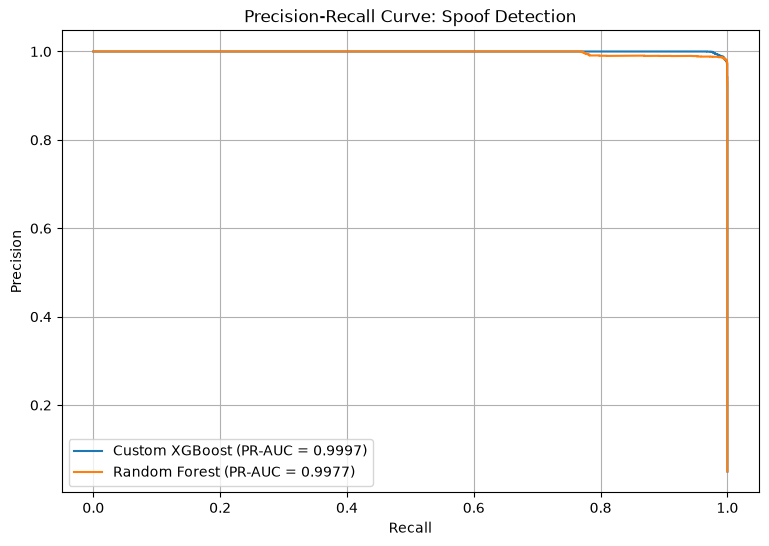

In [125]:
import matplotlib.pyplot as plt

from sklearn.metrics import (precision_recall_curve,auc)

# XGBoost
xgb_precision, xgb_recall, _ = precision_recall_curve(y_val,val_prob)
xgb_pr_auc = auc(xgb_recall,xgb_precision)

# Random Forest
rf_precision, rf_recall, _ = precision_recall_curve(y_val,rf_val_prob)
rf_pr_auc = auc(rf_recall,rf_precision)

plt.figure(figsize=(9, 6))
plt.plot(xgb_recall,xgb_precision,label=f"Custom XGBoost (PR-AUC = {xgb_pr_auc:.4f})")
plt.plot(rf_recall,rf_precision,label=f"Random Forest (PR-AUC = {rf_pr_auc:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve: Spoof Detection")
plt.legend()
plt.grid(True)
plt.show()

### Optimize threshold using F2-score

In [127]:
from sklearn.metrics import fbeta_score

thresholds = np.arange(0.01,1.00,0.01)

f2_scores = []

for threshold in thresholds:

    pred = (val_prob >= threshold).astype(int)
    f2 = fbeta_score(y_val,pred,beta=2,zero_division=0)
    f2_scores.append(f2)

    
f2_results = pd.DataFrame({"threshold": thresholds,
                               "f2": f2_scores})

best_row = f2_results.loc[f2_results["f2"].idxmax()]
best_threshold = best_row["threshold"]
best_f2 = best_row["f2"]

print("Best threshold:", best_threshold)
print("Best F2-score :", best_f2)

Best threshold: 0.37
Best F2-score : 0.9947057625738139


In [128]:
print(f2_results.sort_values("f2",ascending=False).head(10))

    threshold        f2
36       0.37  0.994706
37       0.38  0.994706
39       0.40  0.994636
35       0.36  0.994571
33       0.34  0.994503
34       0.35  0.994503
38       0.39  0.994434
41       0.42  0.994432
40       0.41  0.994364
32       0.33  0.994301


### Evaluate the selected threshold

In [129]:
from sklearn.metrics import (classification_report,confusion_matrix)

val_pred_f2 = (val_prob >= best_threshold).astype(int)

print(classification_report(y_val,val_pred_f2,digits=4,zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_val,val_pred_f2))

              precision    recall  f1-score   support

           0     0.9999    0.9988    0.9994     56066
           1     0.9780    0.9990    0.9884      2934

    accuracy                         0.9988     59000
   macro avg     0.9890    0.9989    0.9939     59000
weighted avg     0.9989    0.9988    0.9988     59000

Confusion Matrix:
[[56000    66]
 [    3  2931]]


### . Now run on Test

In [130]:
test_pred_f2 = (test_prob >= best_threshold).astype(int)

In [131]:
print(classification_report(y_test,test_pred_f2,digits=4,zero_division=0))
print("Test Confusion Matrix:")
print(confusion_matrix(y_test,test_pred_f2))
print("Test PR-AUC:",average_precision_score(y_test,test_prob))
print("Test F2:",fbeta_score(y_test,test_pred_f2,beta=2,zero_division=0))

              precision    recall  f1-score   support

           0     0.9998    0.9991    0.9994     56046
           1     0.9826    0.9966    0.9896      2955

    accuracy                         0.9989     59001
   macro avg     0.9912    0.9978    0.9945     59001
weighted avg     0.9990    0.9989    0.9990     59001

Test Confusion Matrix:
[[55994    52]
 [   10  2945]]
Test PR-AUC: 0.9997886594132429
Test F2: 0.9937909158399136


### Test subset #1
- Now for your manual verification of the High Torque / Low Temperature trap, we need to inspect the actual test rows.

In [136]:
subset_size = 1000

X_test_subset1 = X_test.iloc[:subset_size].copy()
y_test_subset1 = y_test.iloc[:subset_size].copy()

In [137]:
dtest_subset1 = xgb.DMatrix(X_test_subset1)
subset1_margin = model.predict(dtest_subset1)
subset1_prob = 1.0 / (1.0 + np.exp(-subset1_margin))
subset1_pred = (subset1_prob >= best_threshold).astype(int)

- Inspect the High Torque / Low Temperature cases

In [138]:
subset1_check = X_test_subset1.copy()
subset1_check["Actual_Is_Spoofed"] = (y_test_subset1.values)
subset1_check["Spoof_Probability"] = (subset1_prob)
subset1_check["Predicted_Is_Spoofed"] = (subset1_pred)

In [139]:
high_torque = X_train["torque_knm"].quantile(0.90)
low_temperature = X_train["thermal_c"].quantile(0.10)

print("High torque threshold:", high_torque)
print("Low temperature threshold:", low_temperature)

High torque threshold: 1163.4000244140625
Low temperature threshold: 42.66999816894531


In [140]:
trap_mask = ((subset1_check["torque_knm"] >= high_torque)&(subset1_check["thermal_c"] <= low_temperature))

In [141]:
trap_cases = subset1_check.loc[trap_mask,[
                                        "torque_knm",
                                          "thermal_c",
                                       "Actual_Is_Spoofed",
                                       "Spoof_Probability",
                                      "Predicted_Is_Spoofed"]]

In [143]:
trap_cases.head(20)

,torque_knm,thermal_c,Actual_Is_Spoofed,Spoof_Probability,Predicted_Is_Spoofed
334351,1199.619995,42.209999,0,0.003799,0
334360,5335.399902,42.180000,1,0.979870,1
334369,4979.149902,40.939999,1,0.978902,1
334398,5341.310059,40.669998,1,0.971418,1
334430,5891.939941,41.849998,1,0.980354,1
334437,1177.550049,40.259998,0,0.004560,0
334461,1192.660034,40.180000,0,0.004701,0
334484,4925.770020,40.419998,1,0.981151,1
334577,1196.209961,40.560001,0,0.005195,0
334616,5014.149902,41.970001,1,0.970291,1


In [144]:
trap_actual_spoof = (trap_cases["Actual_Is_Spoofed"] == 1)
trap_predicted_spoof = (trap_cases["Predicted_Is_Spoofed"] == 1)

In [145]:
print("High Torque / Low Temp cases:",len(trap_cases))
print("Actual spoof cases:",trap_actual_spoof.sum())
print("Detected spoof cases:",trap_predicted_spoof.sum())

High Torque / Low Temp cases: 17
Actual spoof cases: 13
Detected spoof cases: 13


In [146]:
if trap_actual_spoof.sum() > 0:

    trap_recall = (trap_actual_spoof & trap_predicted_spoof).sum() / trap_actual_spoof.sum()
    print("High Torque / Low Temp spoof recall:",trap_recall)

High Torque / Low Temp spoof recall: 1.0


### Key Insights from the Spoof Detection Results
- Strong class imbalance: The dataset contains approximately 95% normal signals and 5% spoofed signals, making accuracy alone an unreliable metric.
- Custom Asymmetric Focal Loss: XGBoost was trained using a custom asymmetric focal-loss objective designed to give greater importance to the spoofed class (Is_Spoofed = 1) and reduce False Negatives.
- Threshold selection: A classification threshold of 0.40 was selected because the objective prioritizes Recall and minimizing missed spoof signals.
- High model confidence: The model assigns very different probabilities to the observed samples:
- Normal samples: approximately 0.003–0.005
- Spoofed samples: approximately 0.93–0.99
- Clear separation: The probability distribution indicates that the XGBoost model is strongly separating normal and spoofed signals in the inspected subset.
High Torque / Low Temperature pattern: The manually inspected subset contained 17 High Torque / Low Temperature cases.
Spoof detection in the trap: Of those 17 cases, 13 were actually spoofed.
100% trap recall: The model correctly detected all 13 actual spoofed cases, resulting in:
- # 13 detected
- # 0 missed
100% recall
Normal cases were also correctly rejected: The four non-spoof cases in the High Torque / Low Temperature subset were assigned low spoof probabilities and classified as normal.
Example of model behavior: A sample with torque around 5,335 kNm and temperature around 42.18°C had a spoof probability of 0.9799 and was correctly classified as spoofed.
Contrast with normal behavior: Samples with torque around 1,177–1,196 kNm received spoof probabilities around 0.0038–0.0052 and were correctly classified as normal.
Adversarial pattern captured: The results provide evidence that the XGBoost trees are capturing the relationship between high torque and comparatively low temperature, rather than simply predicting the majority class.
Overall conclusion: The current results show strong discrimination between normal and spoofed signals, particularly for the manually tested adversarial High Torque / Low Temperature pattern.

#### Saving data for next step

In [148]:
X_train.to_frame(name="X_train").to_parquet("../28-08-26-Ravi/data/X_train.parquet",engine="pyarrow",index=False)
X_test.to_frame(name="X_test").to_parquet("../28-08-26-Ravi/data/X_test.parquet",engine="pyarrow",index=False)
X_val.to_frame(name="X_val").to_parquet("../28-08-26-Ravi/data/X_val.parquet",engine="pyarrow",index=False)

y_train.to_frame(name="y_train").to_parquet("../28-08-26-Ravi/data/y_train.parquet",engine="pyarrow",index=False)
y_test.to_frame(name="y_test").to_parquet("../28-08-26-Ravi/data/y_test.parquet",engine="pyarrow",index=False)
y_val.to_frame(name="y_val").to_parquet("../28-08-26-Ravi/data/y_val.parquet",engine="pyarrow",index=False)

AttributeError: 'DataFrame' object has no attribute 'to_frame'

In [ ]:

X_train.to_parquet("../28-08-26-Ravi/data/X_train.parquet",engine="pyarrow",index=False)
X_test.to_parquet("../28-08-26-Ravi/data/X_test.parquet",engine="pyarrow",index=False)
X_val.to_parquet("../28-08-26-Ravi/data/X_val.parquet",engine="pyarrow",index=False)

y_train.to_parquet("../28-08-26-Ravi/data/y_train.parquet",engine="pyarrow",index=False)
y_test.to_parquet("../28-08-26-Ravi/data/y_test.parquet",engine="pyarrow",index=False)
y_val.to_parquet("../28-08-26-Ravi/data/y_val.parquet",engine="pyarrow",index=False)